### Feature Engineering

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

datos = pd.read_csv('../../data/silver/cleaned_houses_inmuebles.csv')
datos.info()


<class 'pandas.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Total_area_m2  499 non-null    int64  
 1   Built_area_m2  499 non-null    int64  
 2   Rooms          499 non-null    int64  
 3   Bathrooms      499 non-null    int64  
 4   HalfBathrooms  499 non-null    int64  
 5   Parkings       499 non-null    int64  
 6   Colonia        499 non-null    str    
 7   Price          499 non-null    int64  
 8   PropertyType   499 non-null    str    
 9   Latitude       499 non-null    float64
 10  Longitude      499 non-null    float64
dtypes: float64(2), int64(7), str(2)
memory usage: 43.0 KB


<Axes: xlabel='Price', ylabel='Count'>

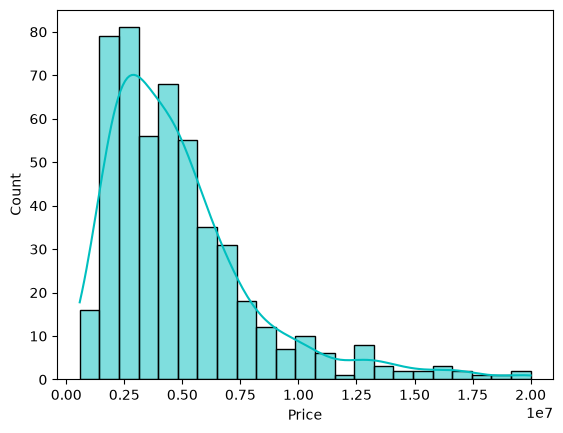

In [11]:
import seaborn as sns
sns.histplot(data=datos, x='Price', color='c', kde=True)


In [12]:
datos['Price'].describe()

count    4.990000e+02
mean     4.895285e+06
std      3.259126e+06
min      5.800000e+05
25%      2.600000e+06
50%      4.190000e+06
75%      6.000000e+06
max      2.000000e+07
Name: Price, dtype: float64

In [13]:
prueba = datos[datos['Price'] <= 1.00e7]
prueba['Price'].describe()

count    4.610000e+02
mean     4.185406e+06
std      2.054807e+06
min      5.800000e+05
25%      2.469000e+06
50%      3.950000e+06
75%      5.400000e+06
max      1.000000e+07
Name: Price, dtype: float64

<Axes: xlabel='Price', ylabel='Count'>

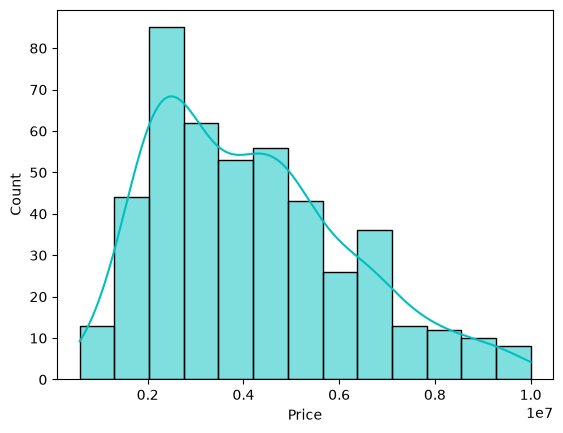

In [14]:
import seaborn as sns
sns.histplot(data=prueba, x='Price', color='c', kde=True)


In [15]:
datos = prueba

In [16]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
import warnings

# Ignorar advertencias específicas de scikit-learn para una salida de consola más limpia en producción
warnings.filterwarnings('ignore', category=UserWarning)

def generar_reporte_metricas(y_true, y_pred, num_muestras, num_predictores):
    """
    Calcula e imprime las métricas de evaluación requeridas.
    """
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # R² Ajustado
    r2_ajustado = 1 - (1 - r2) * ((num_muestras - 1) / (num_muestras - num_predictores - 1))
    
    print("-" * 50)
    print("REPORTE DE EVALUACIÓN EN CONJUNTO DE PRUEBA")
    print("-" * 50)
    print(f"MAE (Error Absoluto Medio):          {mae:,.2f}")
    print(f"MSE (Error Cuadrático Medio):        {mse:,.2f}")
    print(f"RMSE (Raíz del MSE):                 {rmse:,.2f}")
    print(f"MAPE (Error Porcentual Abs. Medio):  {mape:.4f} ({mape*100:.2f}%)")
    print(f"R² (Coeficiente de Determinación):   {r2:.4f}")
    print(f"R² Ajustado:                         {r2_ajustado:.4f}")
    print("-" * 50)

def entrenar_y_evaluar_pipeline(datos: pd.DataFrame):
    """
    Función principal que ejecuta el pipeline de preprocesamiento, 
    búsqueda de hiperparámetros y evaluación de modelos.
    """
    # 1. Separación de características y variable objetivo
    X = datos.drop(columns=['Price'])
    y = datos['Price']
    
    # 2. División en entrenamiento y prueba (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # 3. Definición de grupos de columnas
    cols_sesgadas = ['Total_area_m2', 'Built_area_m2']
    cols_conteos = ['Rooms', 'Bathrooms', 'HalfBathrooms', 'Parkings']
    cols_categoricas = ['Colonia', 'PropertyType']
    cols_geoespaciales = ['Latitude', 'Longitude']
    
    # 4. Creación de transformadores específicos
    # Log1p maneja ceros de manera segura. MinMaxScaler acota la salida.
    transformador_sesgado = Pipeline(steps=[
        ('log_transform', FunctionTransformer(np.log1p, validate=False)),
        ('minmax_scaler', MinMaxScaler())
    ])
    
    # 5. Ensamblaje del ColumnTransformer
    preprocesador = ColumnTransformer(
        transformers=[
            ('sesgadas', transformador_sesgado, cols_sesgadas),
            ('conteos', RobustScaler(), cols_conteos),
            # Requiere scikit-learn >= 1.2 para soportar handle_unknown='ignore' junto con drop='first'
            ('categoricas', OneHotEncoder(handle_unknown='ignore', drop='first'), cols_categoricas),
            ('geoespaciales', 'passthrough', cols_geoespaciales)
        ],
        remainder='drop' # Por seguridad, descartamos cualquier columna no especificada
    )
    
    # 6. Definición de modelos y sus espacios de búsqueda (Grids)
    modelos_y_parametros = [
        {
            'nombre': 'Ridge',
            'estimador': Ridge(random_state=42),
            'parametros': {
                'modelo__alpha': [0.1, 1.0, 10.0, 100.0]
            }
        },
        {
            'nombre': 'RandomForest',
            'estimador': RandomForestRegressor(random_state=42, n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 200],
                'modelo__max_depth': [None, 10, 20],
                'modelo__min_samples_split': [2, 5]
            }
        },
        {
            'nombre': 'GradientBoosting',
            'estimador': GradientBoostingRegressor(random_state=42),
            'parametros': {
                'modelo__n_estimators': [100, 200],
                'modelo__learning_rate': [0.01, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7]
            }
        },
        {
            'nombre': 'XGBoost',
            'estimador': XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 200],
                'modelo__learning_rate': [0.01, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7],
                'modelo__subsample': [0.8, 1.0]
            }
        }
    ]
    
    # Configuración de validación cruzada
    estrategia_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    mejor_modelo_global = None
    mejor_puntuacion_global = float('-inf')
    nombre_mejor_modelo = ""
    
    print("Iniciando búsqueda de hiperparámetros...\n")
    
    # 7. Iteración sobre modelos para optimización
    for config in modelos_y_parametros:
        pipeline = Pipeline(steps=[
            ('preprocesador', preprocesador),
            ('modelo', config['estimador'])
        ])
        
        # Utilizamos RandomizedSearchCV para eficiencia, buscando maximizar R2 (neg_mean_squared_error también es válido)
        busqueda = RandomizedSearchCV(
            pipeline,
            param_distributions=config['parametros'],
            n_iter=10, # Limita las combinaciones aleatorias para agilizar
            cv=estrategia_cv,
            scoring='r2',
            n_jobs=-1,
            random_state=42
        )
        
        busqueda.fit(X_train, y_train)
        
        puntuacion_actual = busqueda.best_score_
        print(f"Modelo: {config['nombre']:<18} | Mejor CV R²: {puntuacion_actual:.4f}")
        
        if puntuacion_actual > mejor_puntuacion_global:
            mejor_puntuacion_global = puntuacion_actual
            mejor_modelo_global = busqueda.best_estimator_
            nombre_mejor_modelo = config['nombre']
            
    print(f"\nMejor modelo seleccionado: {nombre_mejor_modelo} con hiperparámetros:")
    print(mejor_modelo_global.named_steps['modelo'].get_params())
    print("\nEvaluando en el conjunto de prueba oculto...")
    
    # 8. Evaluación final del mejor modelo
    y_pred = mejor_modelo_global.predict(X_test)
    
    # Para calcular el R2 ajustado, necesitamos el número de predictores después del preprocesamiento
    # Extraemos la matriz transformada del X_test
    X_test_transformado = mejor_modelo_global.named_steps['preprocesador'].transform(X_test)
    num_predictores = X_test_transformado.shape[1]
    num_muestras = len(y_test)
    
    generar_reporte_metricas(y_test, y_pred, num_muestras, num_predictores)
    
    return mejor_modelo_global

# =====================================================================
# Instrucción de ejecución (asumiendo que 'datos' ya está en memoria):
# =====================================================================
pipeline_produccion = entrenar_y_evaluar_pipeline(datos)

Iniciando búsqueda de hiperparámetros...

Modelo: Ridge              | Mejor CV R²: 0.6529
Modelo: RandomForest       | Mejor CV R²: 0.6338
Modelo: GradientBoosting   | Mejor CV R²: 0.6026
Modelo: XGBoost            | Mejor CV R²: 0.6247

Mejor modelo seleccionado: Ridge con hiperparámetros:
{'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': 42, 'solver': 'auto', 'tol': 0.0001}

Evaluando en el conjunto de prueba oculto...
--------------------------------------------------
REPORTE DE EVALUACIÓN EN CONJUNTO DE PRUEBA
--------------------------------------------------
MAE (Error Absoluto Medio):          803,966.11
MSE (Error Cuadrático Medio):        1,506,164,637,785.74
RMSE (Raíz del MSE):                 1,227,258.99
MAPE (Error Porcentual Abs. Medio):  0.3668 (36.68%)
R² (Coeficiente de Determinación):   0.6602
R² Ajustado:                         7.2532
--------------------------------------------------


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

def generar_reporte_metricas(y_true, y_pred, num_muestras, num_predictores):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print("-" * 50)
    print("REPORTE DE EVALUACIÓN EN CONJUNTO DE PRUEBA")
    print("-" * 50)
    print(f"MAE:          {mae:,.2f}")
    print(f"MSE:          {mse:,.2f}")
    print(f"RMSE:         {rmse:,.2f}")
    print(f"MAPE:         {mape:.4f} ({mape*100:.2f}%)")
    print(f"R²:           {r2:.4f}")
    
    # Validación matemática para el R² Ajustado (Grados de libertad)
    if num_muestras > num_predictores + 1:
        r2_ajustado = 1 - (1 - r2) * ((num_muestras - 1) / (num_muestras - num_predictores - 1))
        print(f"R² Ajustado:  {r2_ajustado:.4f}")
    else:
        print("R² Ajustado:  No calculable (predictores >= muestras - 1)")
    print("-" * 50)

def entrenar_y_evaluar_pipeline_extendido(datos: pd.DataFrame):
    X = datos.drop(columns=['Price'])
    y = datos['Price']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    preprocesador = ColumnTransformer(
        transformers=[
            ('sesgadas', Pipeline([
                ('log_transform', FunctionTransformer(np.log1p, validate=False)),
                ('minmax_scaler', MinMaxScaler())
            ]), ['Total_area_m2', 'Built_area_m2']),
            ('conteos', RobustScaler(), ['Rooms', 'Bathrooms', 'HalfBathrooms', 'Parkings']),
            ('categoricas', OneHotEncoder(handle_unknown='ignore', drop='first'), ['Colonia', 'PropertyType']),
            ('geoespaciales', 'passthrough', ['Latitude', 'Longitude'])
        ],
        remainder='drop'
    )
    
    # Diccionario masivo de modelos e hiperparámetros
    modelos_y_parametros = [
        {
            'nombre': 'CatBoost',
            'estimador': CatBoostRegressor(verbose=0, random_state=42, thread_count=-1),
            'parametros': {
                'modelo__iterations': [200, 500, 1000],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__depth': [4, 6, 8, 10],
                'modelo__l2_leaf_reg': [1, 3, 5, 10]
            }
        },
        {
            'nombre': 'LightGBM',
            'estimador': LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [-1, 5, 10, 20],
                'modelo__num_leaves': [31, 63, 127],
                'modelo__subsample': [0.7, 0.8, 1.0]
            }
        },
        {
            'nombre': 'XGBoost',
            'estimador': XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500, 1000],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7, 9],
                'modelo__subsample': [0.6, 0.8, 1.0],
                'modelo__colsample_bytree': [0.6, 0.8, 1.0]
            }
        },
        {
            'nombre': 'RandomForest',
            'estimador': RandomForestRegressor(random_state=42, n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500, 800],
                'modelo__max_depth': [None, 10, 20, 30, 50],
                'modelo__min_samples_split': [2, 5, 10, 15],
                'modelo__min_samples_leaf': [1, 2, 4]
            }
        },
        {
            'nombre': 'GradientBoosting',
            'estimador': GradientBoostingRegressor(random_state=42),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7, 9],
                'modelo__subsample': [0.7, 0.8, 1.0]
            }
        },
        {
            'nombre': 'Ridge',
            'estimador': Ridge(random_state=42),
            'parametros': {
                'modelo__alpha': np.logspace(-3, 3, 100),
                'modelo__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga']
            }
        },
        {
            'nombre': 'ElasticNet',
            'estimador': ElasticNet(random_state=42, max_iter=10000),
            'parametros': {
                'modelo__alpha': np.logspace(-3, 2, 50),
                'modelo__l1_ratio': np.linspace(0.01, 1.0, 20)
            }
        },
        {
            'nombre': 'SVR',
            'estimador': SVR(),
            'parametros': {
                'modelo__kernel': ['linear', 'poly', 'rbf'],
                'modelo__C': [0.1, 1, 10, 100, 1000],
                'modelo__gamma': ['scale', 'auto', 0.1, 1],
                'modelo__epsilon': [0.01, 0.1, 0.5, 1]
            }
        }
    ]
    
    estrategia_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    mejor_modelo_global = None
    mejor_puntuacion_global = float('-inf')
    nombre_mejor_modelo = ""
    
    print("Iniciando búsqueda extendida de hiperparámetros...\n")
    
    for config in modelos_y_parametros:
        pipeline = Pipeline(steps=[
            ('preprocesador', preprocesador),
            ('modelo', config['estimador'])
        ])
        
        busqueda = RandomizedSearchCV(
            pipeline,
            param_distributions=config['parametros'],
            n_iter=10, # Aumentado significativamente al haber buen hardware
            cv=estrategia_cv,
            scoring='r2',
            n_jobs=-1,
            random_state=42
        )
        
        # SVR y ElasticNet pueden quejarse silenciosamente con combinaciones raras, pasamos limpio
        try:
            busqueda.fit(X_train, y_train)
            puntuacion_actual = busqueda.best_score_
            print(f"Modelo: {config['nombre']:<18} | Mejor CV R²: {puntuacion_actual:.4f}")
            
            if puntuacion_actual > mejor_puntuacion_global:
                mejor_puntuacion_global = puntuacion_actual
                mejor_modelo_global = busqueda.best_estimator_
                nombre_mejor_modelo = config['nombre']
        except Exception as e:
            print(f"Modelo: {config['nombre']:<18} | Falló durante el entrenamiento.")
            
    print(f"\nMejor modelo seleccionado: {nombre_mejor_modelo} con hiperparámetros:")
    # Filtramos para mostrar solo los parámetros del modelo (quitando el prefijo 'modelo__')
    params_modelo = mejor_modelo_global.named_steps['modelo'].get_params()
    print({k: v for k, v in params_modelo.items() if v is not None})
    
    print("\nEvaluando en el conjunto de prueba oculto...")
    y_pred = mejor_modelo_global.predict(X_test)
    
    X_test_transformado = mejor_modelo_global.named_steps['preprocesador'].transform(X_test)
    num_predictores = X_test_transformado.shape[1]
    num_muestras = len(y_test)
    
    generar_reporte_metricas(y_test, y_pred, num_muestras, num_predictores)
    
    return mejor_modelo_global

# Ejecutar con:
mejor_modelo = entrenar_y_evaluar_pipeline_extendido(datos)

Iniciando búsqueda extendida de hiperparámetros...

Modelo: CatBoost           | Mejor CV R²: 0.6523
Modelo: LightGBM           | Mejor CV R²: 0.6257
Modelo: XGBoost            | Mejor CV R²: 0.6458
Modelo: RandomForest       | Mejor CV R²: 0.6452
Modelo: GradientBoosting   | Mejor CV R²: 0.6314


d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
140 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
35 fits failed with the following error:
Traceback (most recent call last):
  File "d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-package

Modelo: Ridge              | Mejor CV R²: 0.6539
Modelo: ElasticNet         | Mejor CV R²: 0.6543


KeyboardInterrupt: 

In [ ]:
# Necesitarás instalar: pip install category_encoders
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, RobustScaler, OneHotEncoder
from category_encoders import TargetEncoder

# Importes de los modelos (asumiendo que ya los tienes en tu entorno)
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.svm import SVR

def entrenar_y_evaluar_pipeline_optimizado(datos: pd.DataFrame):
    X = datos.drop(columns=['Price'])
    y = datos['Price']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # 1. Transformación Logarítmica de la variable objetivo (y)
    # Esto ayuda a que el modelo prediga valores más pequeños y normalizados.
    y_train_log = np.log1p(y_train)
    
    # 2. Pipeline de Preprocesamiento
    preprocesador = ColumnTransformer(
        transformers=[
            ('sesgadas', Pipeline([
                ('log_transform', FunctionTransformer(np.log1p, validate=False)),
                ('minmax_scaler', MinMaxScaler())
            ]), ['Total_area_m2', 'Built_area_m2']),
            
            ('conteos', RobustScaler(), ['Rooms', 'Bathrooms', 'HalfBathrooms', 'Parkings']),
            
            # Baja cardinalidad: OneHotEncoder
            ('cat_baja', OneHotEncoder(handle_unknown='ignore', drop='first'), ['PropertyType']),
            
            # Alta cardinalidad: TargetEncoder
            # Evita la alta dimensionalidad transformando las N categorías de Colonia en 1 sola columna
            # basada en la media de la variable objetivo (suavizada para evitar sobreajuste)
            ('cat_alta', TargetEncoder(smoothing=10), ['Colonia']),
            
            ('geoespaciales', 'passthrough', ['Latitude', 'Longitude'])
        ],
        remainder='drop'
    )
    
    # Diccionario masivo de modelos e hiperparámetros
    modelos_y_parametros = [
        {
            'nombre': 'CatBoost',
            'estimador': CatBoostRegressor(verbose=0, random_state=42, thread_count=-1),
            'parametros': {
                'modelo__iterations': [200, 500, 1000],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__depth': [4, 6, 8, 10],
                'modelo__l2_leaf_reg': [1, 3, 5, 10]
            }
        },
        {
            'nombre': 'LightGBM',
            'estimador': LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [-1, 5, 10, 20],
                'modelo__num_leaves': [31, 63, 127],
                'modelo__subsample': [0.7, 0.8, 1.0]
            }
        },
        {
            'nombre': 'XGBoost',
            'estimador': XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500, 1000],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7, 9],
                'modelo__subsample': [0.6, 0.8, 1.0],
                'modelo__colsample_bytree': [0.6, 0.8, 1.0]
            }
        },
        {
            'nombre': 'RandomForest',
            'estimador': RandomForestRegressor(random_state=42, n_jobs=-1),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500, 800],
                'modelo__max_depth': [None, 10, 20, 30, 50],
                'modelo__min_samples_split': [2, 5, 10, 15],
                'modelo__min_samples_leaf': [1, 2, 4]
            }
        },
        {
            'nombre': 'GradientBoosting',
            'estimador': GradientBoostingRegressor(random_state=42),
            'parametros': {
                'modelo__n_estimators': [100, 300, 500],
                'modelo__learning_rate': [0.01, 0.05, 0.1, 0.2],
                'modelo__max_depth': [3, 5, 7, 9],
                'modelo__subsample': [0.7, 0.8, 1.0]
            }
        },
        {
            'nombre': 'Ridge',
            'estimador': Ridge(random_state=42),
            'parametros': {
                'modelo__alpha': np.logspace(-3, 3, 100),
                'modelo__solver': ['auto', 'lsqr', 'sparse_cg', 'sag', 'lbfgs']
            }
        },
        {
            'nombre': 'ElasticNet',
            'estimador': ElasticNet(random_state=42, max_iter=10000),
            'parametros': {
                'modelo__alpha': np.logspace(-3, 2, 50),
                'modelo__l1_ratio': np.linspace(0.01, 1.0, 20)
            }
        },
        {
            'nombre': 'SVR',
            'estimador': SVR(),
            'parametros': {
                'modelo__kernel': ['linear', 'poly', 'rbf'],
                'modelo__C': [0.1, 1, 10, 100, 1000],
                'modelo__gamma': ['scale', 'auto', 0.1, 1],
                'modelo__epsilon': [0.01, 0.1, 0.5, 1]
            }
        }
    ]
    
    estrategia_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    mejor_modelo_global = None
    mejor_puntuacion_global = float('-inf')
    nombre_mejor_modelo = ""
    
    print("Iniciando búsqueda extendida de hiperparámetros...\n")
    
    for config in modelos_y_parametros:
        pipeline = Pipeline(steps=[
            ('preprocesador', preprocesador),
            ('modelo', config['estimador'])
        ])
        
        busqueda = RandomizedSearchCV(
            pipeline,
            param_distributions=config['parametros'],
            n_iter=50, 
            cv=estrategia_cv,
            scoring='r2', # El R2 es invariante a la escala logarítmica, sigue siendo válido
            n_jobs=-1,
            random_state=42
        )
        
        try:
            # Entrenamos usando y_train_log
            busqueda.fit(X_train, y_train_log)
            puntuacion_actual = busqueda.best_score_
            print(f"Modelo: {config['nombre']:<18} | Mejor CV R²: {puntuacion_actual:.4f}")
            
            if puntuacion_actual > mejor_puntuacion_global:
                mejor_puntuacion_global = puntuacion_actual
                mejor_modelo_global = busqueda.best_estimator_
                nombre_mejor_modelo = config['nombre']
        except Exception as e:
            print(f"Modelo: {config['nombre']:<18} | Falló durante el entrenamiento.")
            
    print(f"\nMejor modelo seleccionado: {nombre_mejor_modelo} con hiperparámetros:")
    params_modelo = mejor_modelo_global.named_steps['modelo'].get_params()
    print({k: v for k, v in params_modelo.items() if v is not None})
    
    print("\nEvaluando en el conjunto de prueba oculto...")
    
    # El modelo predice en escala logarítmica
    y_pred_log = mejor_modelo_global.predict(X_test)
    
    # Revertimos la predicción a la escala original de precios
    y_pred = np.expm1(y_pred_log)
    
    X_test_transformado = mejor_modelo_global.named_steps['preprocesador'].transform(X_test)
    num_predictores = X_test_transformado.shape[1]
    num_muestras = len(y_test)
    
    # Se pasa y_test original y y_pred original al reporte
    # generar_reporte_metricas(y_test, y_pred, num_muestras, num_predictores)
    
    return mejor_modelo_global

# Ejecutar con:
mejor_modelo_3 = entrenar_y_evaluar_pipeline_optimizado(datos)